In [10]:
!pip install matplotlib seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
# Khai báo thông tin sinh viên
MSSV = "6451071045"
HO_TEN = "Lê Gia Luân"

print(f"Họ và tên: {HO_TEN}")
print(f"MSSV: {MSSV}")
# 1. Nhập dữ liệu và thống kê thông tin cơ bản
df = pd.read_csv('titanic.csv', dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

print("=== Thống kê tổng quan dữ liệu ===")
df.info()
print("\n=== Chỉ số thống kê mô tả ===")
print(df.describe())

Họ và tên: Lê Gia Luân
MSSV: 6451071045
=== Thống kê tổng quan dữ liệu ===
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB

=== Chỉ số thống kê mô tả ===
            pclass     survived          age        sibsp        parch  \
count  1309.000000  1309


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd
# Khai báo thông tin sinh viên
MSSV = "6451071045"
HO_TEN = "Lê Gia Luân"

print(f"Họ và tên: {HO_TEN}")
print(f"MSSV: {MSSV}")
# 1. Đọc file dữ liệu vào biến df trước
df = pd.read_csv('titanic.csv')

# 2. Chạy đoạn code thống kê dữ liệu thiếu
total = df.isnull().sum().sort_values(ascending=False)
percent = (round(df.isnull().sum() / df.isnull().count() * 100, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', '%'])

print(missing_data.head(5))
total = df.isnull().sum().sort_values(ascending=False)
percent = (round(df.isnull().sum() / df.isnull().count() * 100, 1)).sort_values(ascending=False)
missing_data = pd.concat([total, percent], axis=1, keys=['Total', '%'])
print(missing_data.head(5))

Họ và tên: Lê Gia Luân
MSSV: 6451071045
           Total     %
body        1188  90.8
cabin       1014  77.5
boat         823  62.9
home.dest    564  43.1
age          263  20.1
           Total     %
body        1188  90.8
cabin       1014  77.5
boat         823  62.9
home.dest    564  43.1
age          263  20.1


Họ và tên: Lê Gia Luân
MSSV: 6451071045


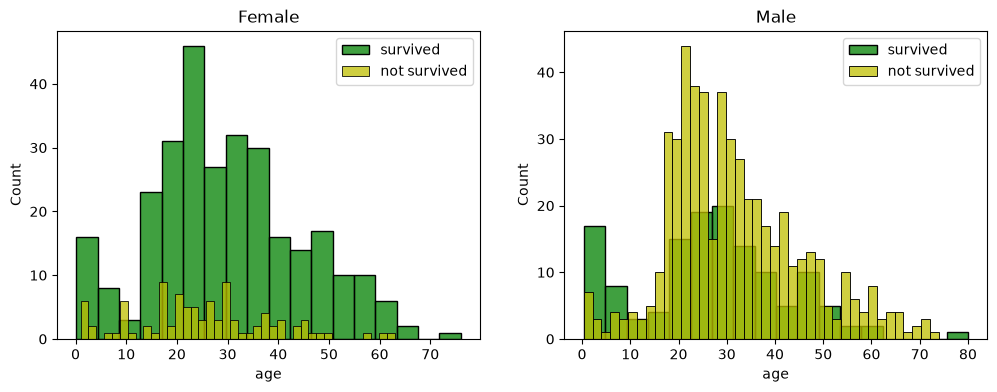

In [11]:
# Khai báo thông tin sinh viên
MSSV = "6451071045"
HO_TEN = "Lê Gia Luân"

print(f"Họ và tên: {HO_TEN}")
print(f"MSSV: {MSSV}")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4))
women = df[df['sex'] == 'female']
men = df[df['sex'] == 'male']

sns.histplot(women[women['survived'] == 1].age.dropna(), bins=18, label='survived', ax=axes[0], color='g', kde=False)
sns.histplot(women[women['survived'] == 0].age.dropna(), bins=40, label='not survived', ax=axes[0], color='y', kde=False)
axes[0].legend()
axes[0].set_title('Female')

sns.histplot(men[men['survived'] == 1].age.dropna(), bins=18, label='survived', ax=axes[1], color='g', kde=False)
sns.histplot(men[men['survived'] == 0].age.dropna(), bins=40, label='not survived', ax=axes[1], color='y', kde=False)
axes[1].legend()
axes[1].set_title('Male')
plt.show()

In [12]:
# 6. Tiền xử lý dữ liệu
deck_map = {"A": 1, "B": 2, "C": 3, "D": 4, "E": 5, "F": 6, "G": 7, "U": 8}
df['cabin'] = df['cabin'].fillna("00")
df['deck'] = df['cabin'].map(lambda x: re.compile("([a-zA-Z]+)").search(x).group() if re.compile("([a-zA-Z]+)").search(x) else 'U')
df['deck'] = df['deck'].map(deck_map).fillna(0).astype(int)

# Xóa các thuộc tính không cần thiết/thiếu quá nhiều
df = df.drop(['cabin', 'ticket', 'boat', 'body', 'home.dest'], axis=1)

# Điền giá trị thiếu ở cột Age ngẫu nhiên trong khoảng [mean - std, mean + std]
np.random.seed(42)
mean_age = df["age"].mean()
std_age = df["age"].std()
is_null_age = df["age"].isnull().sum()
rand_age = np.random.randint(mean_age - std_age, mean_age + std_age, size=is_null_age)
age_slice = df["age"].copy()
age_slice[np.isnan(age_slice)] = rand_age
df["age"] = age_slice.astype(int)

# Điền giá trị thiếu ở Cổng lên tàu bằng Mốt ('S')
df['embarked'] = df['embarked'].fillna('S')

# 7. Biến đổi thuộc tính
df['fare'] = df['fare'].fillna(0).astype(int)

# Trích xuất Danh hiệu (title) từ Tên (name)
titles = {"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}
df['title'] = df.name.str.extract(' ([A-Za-z]+)\.', expand=False)
df['title'] = df['title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['title'] = df['title'].replace(['Mlle', 'Ms'], 'Miss')
df['title'] = df['title'].replace('Mme', 'Mrs')
df['title'] = df['title'].map(titles).fillna(0).astype(int)
df = df.drop(['name'], axis=1)

# Chuyển đổi giới tính và cổng lên tàu thành số
df['sex'] = df['sex'].map({"male": 0, "female": 1})
df['embarked'] = df['embarked'].map({"S": 0, "C": 1, "Q": 2})

# Chia nhóm tuổi (8 nhóm)
df.loc[df['age'] <= 11, 'age'] = 0
df.loc[(df['age'] > 11) & (df['age'] <= 18), 'age'] = 1
df.loc[(df['age'] > 18) & (df['age'] <= 22), 'age'] = 2
df.loc[(df['age'] > 22) & (df['age'] <= 27), 'age'] = 3
df.loc[(df['age'] > 27) & (df['age'] <= 33), 'age'] = 4
df.loc[(df['age'] > 33) & (df['age'] <= 40), 'age'] = 5
df.loc[(df['age'] > 40) & (df['age'] <= 66), 'age'] = 6
df.loc[df['age'] > 66, 'age'] = 7

# Chia nhóm giá vé (6 nhóm)
df.loc[df['fare'] <= 7.91, 'fare'] = 0
df.loc[(df['fare'] > 7.91) & (df['fare'] <= 14.454), 'fare'] = 1
df.loc[(df['fare'] > 14.454) & (df['fare'] <= 31), 'fare'] = 2
df.loc[(df['fare'] > 31) & (df['fare'] <= 99), 'fare'] = 3
df.loc[(df['fare'] > 99) & (df['fare'] <= 250), 'fare'] = 4
df.loc[df['fare'] > 250, 'fare'] = 5

# 8. Tạo thuộc tính mới
df['age_class'] = df['age'] * df['pclass']
df['fare_per_person'] = (df['fare'] / (df['relatives'] + 1)).astype(int)

print("\n=== Dữ liệu sau khi hoàn tất tiền xử lý (10 dòng đầu) ===")
print(df.head(10))

<>:28: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:28: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16080\2948749811.py:28: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  df['title'] = df.name.str.extract(' ([A-Za-z]+)\.', expand=False)


KeyError: 'relatives'

Họ và tên: Lê Gia Luân
MSSV: 6451071045
Số người đi một mình (not_alone = 1): 790
Số người đi cùng người thân (not_alone = 0): 519


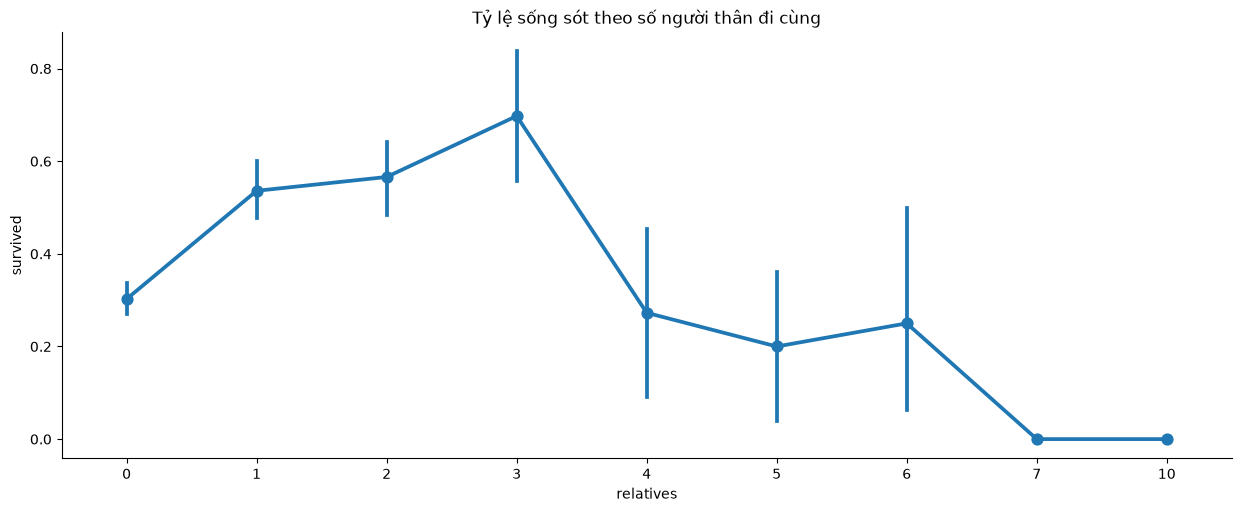

In [15]:
# Khai báo thông tin sinh viên
MSSV = "6451071045"
HO_TEN = "Lê Gia Luân"

print(f"Họ và tên: {HO_TEN}")
print(f"MSSV: {MSSV}")
df['relatives'] = df['sibsp'] + df['parch']
df['not_alone'] = (df['relatives'] == 0).astype(int)

print("Số người đi một mình (not_alone = 1):", df['not_alone'].value_counts()[1])
print("Số người đi cùng người thân (not_alone = 0):", df['not_alone'].value_counts()[0])

sns.catplot(x='relatives', y='survived', data=df, aspect=2.5, kind='point')
plt.title("Tỷ lệ sống sót theo số người thân đi cùng")
plt.show()